# Clasificación y detección de opacidades compatibles con neumonía en radiografías de tórax

**Integrantes:** David Alberto Chaparro Gil (2221939) · Jose David Erazo Soraca (2230076) · Michael Alexander Ortiz Lozada (2191316)

**Dataset:** [RSNA Pneumonia Processed Dataset](https://www.kaggle.com/datasets/iamtapendu/rsna-pneumonia-processed-dataset) (derivado del RSNA Pneumonia Detection Challenge 2018 [1]).

**Objetivos**
1. **Clasificación:** imagen → `Target` (1 = opacidad pulmonar anotada, compatible con posible neumonía; 0 = sin opacidad anotada) con una CNN y *transfer learning*.
2. **Detección:** imagen → cajas delimitadoras (`x, y, width, height`) de las opacidades anotadas.


## 0. Configuración



In [ ]:
import os, sys, json, gc, random, hashlib
EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    !pip install -q kagglehub torchmetrics pycocotools

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import torch
import torch.nn as nn
import torchvision
import torchmetrics
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 0 if os.name == "nt" else 2

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)

def colate_det(batch):
    return tuple(zip(*batch))

def make_loader(ds, batch_size, shuffle=False, detection=False):
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=DEVICE.type == "cuda", persistent_workers=NUM_WORKERS > 0,
                      worker_init_fn=seed_worker, generator=torch.Generator().manual_seed(SEED),
                      collate_fn=colate_det if detection else None)


GUARDAR_EN_DRIVE = True
EJECUCION = "v3"
REENTRENAR = False

if EN_COLAB and GUARDAR_EN_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/proyecto_neumonia") / EJECUCION
else:
    ROOT = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / EJECUCION
RES_DIR, MODEL_DIR = ROOT / "resultados", ROOT / "models"
RES_DIR.mkdir(parents=True, exist_ok=True); MODEL_DIR.mkdir(parents=True, exist_ok=True)
if REENTRENAR:
    for f in MODEL_DIR.glob("*.pt"):
        f.unlink()
print("Modelos y resultados en:", ROOT, "| modelos guardados:", sorted(f.name for f in MODEL_DIR.glob("*.pt")))

def guardar_ck(obj, ruta):

    tmp = ruta.with_suffix(".tmp"); torch.save(obj, tmp); os.replace(tmp, ruta)
def cargar(ruta):
    return torch.load(ruta, map_location=DEVICE, weights_only=True)
def config_simple():
    return json.loads(json.dumps(config, default=str))
metricas, config = {}, {"seed": SEED}
def guardar_fig(nombre):
    plt.savefig(RES_DIR / f"{nombre}.png", dpi=150, bbox_inches="tight")

config["versiones"] = {"python": sys.version.split()[0], "torch": torch.__version__,
                       "torchvision": torchvision.__version__, "torchmetrics": torchmetrics.__version__}
print("Dispositivo:", DEVICE, "|", config["versiones"])

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Modelos y resultados en: /content/drive/MyDrive/proyecto_neumonia/v3 | modelos guardados: ['clasificador_resnet50.pt', 'clasificador_ultimo.pt', 'detector_fasterrcnn.pt', 'detector_ultimo.pt']
Dispositivo: cuda | {'python': '3.13.16', 'torch': '2.11.0+cu130', 'torchvision': '0.26.0+cu130', 'torchmetrics': '1.9.0'}


- Importamos las librerías y fijamos la semilla en 42 para poder repetir los resultados.
- Montamos Drive para guardar los modelos en cada época y retomar si Colab se desconecta.

## 1. Datos

In [ ]:
import kagglehub
DATA_DIR = Path(kagglehub.dataset_download("iamtapendu/rsna-pneumonia-processed-dataset"))
config["dataset"] = "iamtapendu/rsna-pneumonia-processed-dataset"
print(DATA_DIR)

for root, dirs, files in os.walk(DATA_DIR):
    nivel = root.replace(str(DATA_DIR), "").count(os.sep)
    print("  " * nivel + os.path.basename(root) + "/", f"({len(files)} archivos)")
    for f in files[:3]:
        print("  " * (nivel + 1) + f)

Using Colab cache for faster access to the 'rsna-pneumonia-processed-dataset' dataset.
/kaggle/input/rsna-pneumonia-processed-dataset
rsna-pneumonia-processed-dataset/ (2 archivos)
  stage2_train_metadata.csv
  stage2_test_metadata.csv
  Training/ (0 archivos)
    Images/ (26684 archivos)
      7a530f4d-13af-4e4e-bf2e-080c7fb27ffb.png
      86f084ef-539c-404b-9a91-c9a5d5ab3771.png
      673989cb-131a-43fc-8276-710c65ddb2d6.png
    Masks/ (26684 archivos)
      7a530f4d-13af-4e4e-bf2e-080c7fb27ffb.png
      86f084ef-539c-404b-9a91-c9a5d5ab3771.png
      673989cb-131a-43fc-8276-710c65ddb2d6.png
  Test/ (3000 archivos)
    1b66ef47-b795-418f-bc18-1339bc980b8b.png
    1f69bd0a-8e25-4c4e-b5be-f4395f032f58.png
    29d959bb-171d-487d-87b3-8637e30ba480.png


- Descargamos el dataset de Kaggle y revisamos cómo vienen las carpetas.
- Training trae Images y Masks con los mismos nombres; solo usamos Images.

In [ ]:
df = pd.read_csv(DATA_DIR / "stage2_train_metadata.csv")



IMG_DIR = DATA_DIR / "Training" / "Images"
img_paths = {p.stem: p for p in IMG_DIR.glob("*.png")}

filas_antes, ids_antes = len(df), df["patientId"].nunique()
df = df[df["patientId"].isin(img_paths)].reset_index(drop=True)
print(f"Radiografías en Training/Images: {len(img_paths)}")
print(f"Filas del CSV: {filas_antes} -> {len(df)} tras quitar IDs sin imagen ({filas_antes - len(df)} excluidas)")
print(f"IDs únicos: {ids_antes} -> {df['patientId'].nunique()}")
df.head()

Radiografías en Training/Images: 26684
Filas del CSV: 30227 -> 30227 tras quitar IDs sin imagen (0 excluidas)
IDs únicos: 26684 -> 26684


,patientId,x,y,width,height,Target,class,age,sex,modality,position
0,0004cfab-14fd-4e49-80ba-63a80b6bddd6,NaN,NaN,NaN,NaN,0,No Lung Opacity / Not Normal,51,F,CR,PA
1,00313ee0-9eaa-42f4-b0ab-c148ed3241cd,NaN,NaN,NaN,NaN,0,No Lung Opacity / Not Normal,48,F,CR,PA
2,00322d4d-1c29-4943-afc9-b6754be640eb,NaN,NaN,NaN,NaN,0,No Lung Opacity / Not Normal,19,M,CR,AP
3,003d8fa0-6bf1-40ed-b54c-ac657f8495c5,NaN,NaN,NaN,NaN,0,Normal,28,M,CR,PA
4,00436515-870c-4b36-a041-de91049b9ab4,264.0,152.0,213.0,379.0,1,Lung Opacity,32,F,CR,AP


- Cargamos el CSV de anotaciones y dejamos solo los IDs que tienen imagen.
- Cada fila es una caja, por eso hay más filas (30,227) que imágenes (26,684).

## 2. Exploración y auditoría de datos (EDA)



In [ ]:

print("Nulos por columna:")
print(df.isna().sum()[lambda s: s > 0])

contrad_target = (df.groupby("patientId")["Target"].nunique() > 1).sum()
contrad_clase = (df.groupby("patientId")["class"].nunique() > 1).sum()
print(f"IDs con Target contradictorio: {contrad_target} | con clase contradictoria: {contrad_clase}")

pos = df[df["Target"] == 1]
print("Positivos sin caja:", pos[["x", "y", "width", "height"]].isna().any(axis=1).sum())
print("Negativos con caja:", df[df["Target"] == 0][["x", "y", "width", "height"]].notna().any(axis=1).sum())
fuera = ((pos.x < 0) | (pos.y < 0) | (pos.width <= 0) | (pos.height <= 0) |
         (pos.x + pos.width > 1024) | (pos.y + pos.height > 1024)).sum()
print("Cajas fuera del rango 0-1024 o con tamaño <= 0:", fuera)
assert contrad_target == 0 and contrad_clase == 0, "Hay IDs con etiquetas contradictorias"

Nulos por columna:
x         20672
y         20672
width     20672
height    20672
dtype: int64
IDs con Target contradictorio: 0 | con clase contradictoria: 0
Positivos sin caja: 0
Negativos con caja: 0
Cajas fuera del rango 0-1024 o con tamaño <= 0: 0


- Revisamos nulos, etiquetas contradictorias y cajas fuera de la imagen; no hubo problemas.
- Los nulos de x, y, width y height son las imágenes sin opacidad, que no tienen caja.

Imágenes únicas: 26684
        imágenes  proporción
Target                      
0          20672       0.775
1           6012       0.225


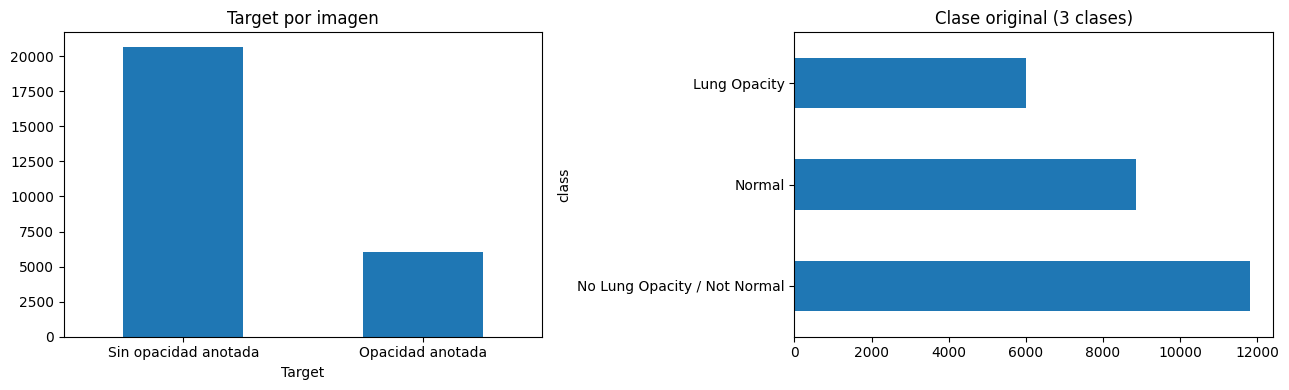

Cajas por imagen con opacidad:
1    2614
2    3266
3     119
4      13
Name: count, dtype: int64


In [ ]:
por_id = df.groupby("patientId")["Target"].max()
meta = df.drop_duplicates("patientId").set_index("patientId")
CLASE = meta["class"]

print("Imágenes únicas:", len(por_id))
print(por_id.value_counts().rename("imágenes").to_frame().assign(
    proporción=por_id.value_counts(normalize=True).round(3)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
por_id.map({0: "Sin opacidad anotada", 1: "Opacidad anotada"}).value_counts().plot.bar(ax=ax[0], title="Target por imagen", rot=0)
CLASE.value_counts().plot.barh(ax=ax[1], title="Clase original (3 clases)")
plt.tight_layout(); guardar_fig("01_clases"); plt.show()

print("Cajas por imagen con opacidad:")
print(df[df["Target"] == 1].groupby("patientId").size().value_counts().sort_index())

- Contando por imagen: 77.5 % sin opacidad y 22.5 % con opacidad.
- Una imagen con opacidad tiene entre 1 y 4 cajas.

,imágenes,con_opacidad,% con opacidad,% del total
position,,,,
AP,12173,4664,38.3,45.6
PA,14511,1348,9.3,54.4


,imágenes,con_opacidad,% con opacidad,% del total
sex,,,,
F,11518,2502,21.7,43.2
M,15166,3510,23.1,56.8


count    26684.0
mean        47.0
std         16.8
min          1.0
25%         34.0
50%         49.0
75%         59.0
max        155.0
Name: age, dtype: float64
Edades > 100: 5 imágenes -> [148, 150, 151, 153, 155]


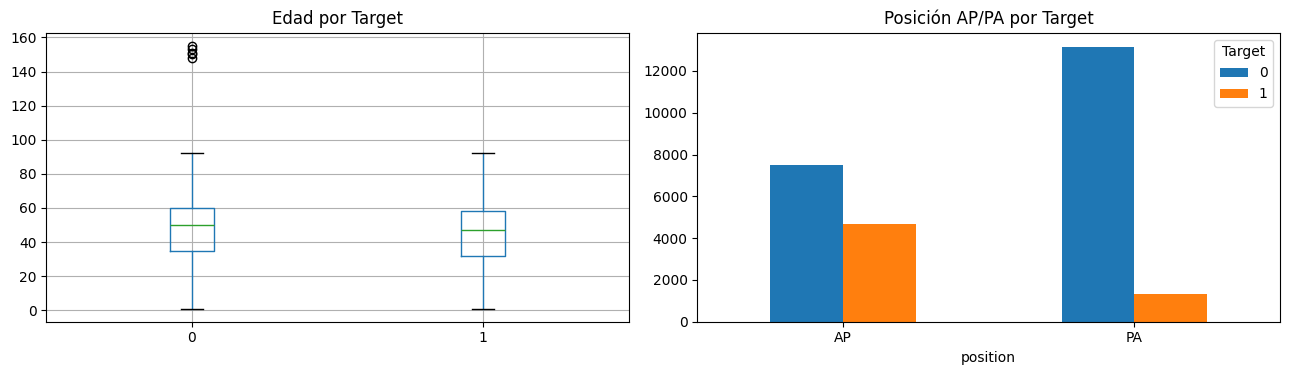

In [ ]:

for col in ["position", "sex"]:
    t = meta.groupby(col)["Target"].agg(imágenes="size", con_opacidad="sum")
    t["% con opacidad"] = (100 * t["con_opacidad"] / t["imágenes"]).round(1)
    t["% del total"] = (100 * t["imágenes"] / len(meta)).round(1)
    display(t)


print(meta["age"].describe().round(1))
raras = meta[meta["age"] > 100]
print(f"Edades > 100: {len(raras)} imágenes ->", sorted(raras["age"].tolist()))
config["edades_mayores_100"] = len(raras)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
meta.boxplot(column="age", by="Target", ax=ax[0]); ax[0].set_title("Edad por Target"); ax[0].set_xlabel("")
meta.groupby(["position", "Target"]).size().unstack().plot.bar(ax=ax[1], title="Posición AP/PA por Target", rot=0)
plt.suptitle(""); plt.tight_layout(); guardar_fig("02_subgrupos"); plt.show()

- Comparamos el % de opacidad por posición de la placa, sexo y edad.
- En placas AP hay 38.3 % con opacidad y en PA solo 9.3 %.
- Hay 5 edades por encima de 100 años; la edad no entra al modelo, así que se dejan.

In [ ]:

def hash_archivo(p):
    h = hashlib.md5()
    with open(p, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()

hashes = pd.Series({pid: hash_archivo(img_paths[pid]) for pid in tqdm(por_id.index, desc="Hash")})
dup = hashes[hashes.duplicated(keep=False)]
grupos_dup = [list(g.index) for _, g in dup.groupby(dup)]
print("Grupos de imágenes idénticas:", len(grupos_dup))
config["duplicados_exactos"] = len(grupos_dup)

Hash:   0%|          | 0/26684 [00:00<?, ?it/s]

Grupos de imágenes idénticas: 1


- Buscamos imágenes repetidas con un hash de cada archivo: solo hay un grupo.

In [ ]:

muestra = random.Random(SEED).sample(list(img_paths.values()), 300)
tamanos = set()
for p in muestra:
    with Image.open(p) as im:
        tamanos.add(im.size)
print("Tamaños encontrados en 300 imágenes:", tamanos)
assert len(tamanos) == 1, "Hay imágenes de distinto tamaño: habría que escalar las cajas por imagen"
IMG_W, IMG_H = tamanos.pop()
SX, SY = IMG_W / 1024, IMG_H / 1024
print(f"Factor de escala de cajas: x={SX}, y={SY}")

Tamaños encontrados en 300 imágenes: {(1024, 1024)}
Factor de escala de cajas: x=1.0, y=1.0


- Todas las imágenes son de 1024 x 1024, así que las cajas del CSV no se reescalan.

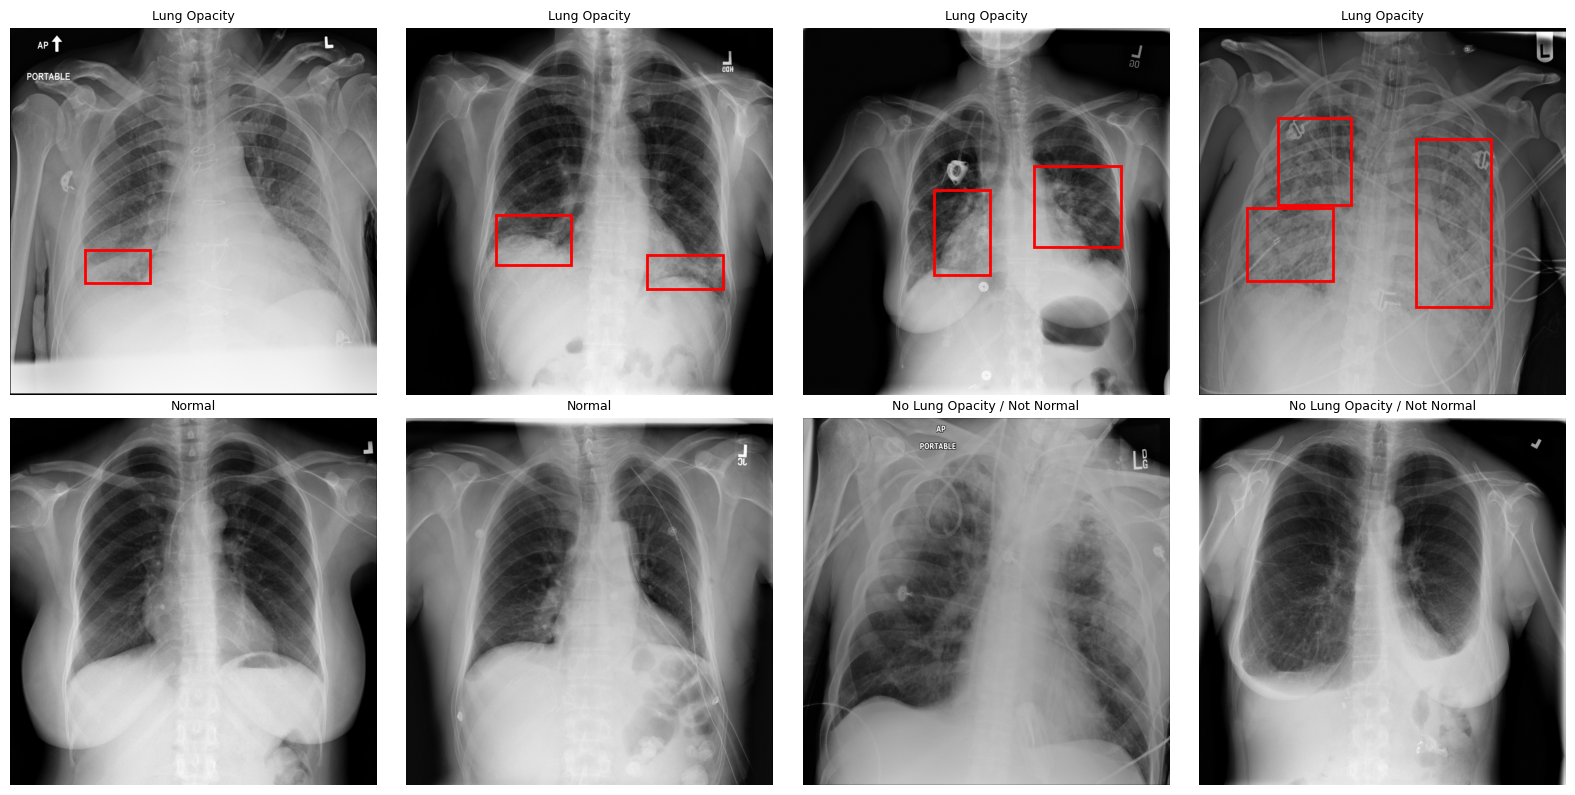

In [ ]:
CAJAS = {}
for r in df[df["Target"] == 1].itertuples():
    CAJAS.setdefault(r.patientId, []).append([r.x * SX, r.y * SY, (r.x + r.width) * SX, (r.y + r.height) * SY])

def mostrar(pid, ax, titulo=None):
    with Image.open(img_paths[pid]) as im:
        ax.imshow(im.convert("L"), cmap="gray")
    for x1, y1, x2, y2 in CAJAS.get(pid, []):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="red", linewidth=2))
    ax.set_title(titulo or CLASE[pid], fontsize=9); ax.axis("off")


n_cajas = pd.Series({k: len(v) for k, v in CAJAS.items()})
ejemplos = [pid for n, k in [(1, 1), (2, 2), (3, 1)] for pid in n_cajas[n_cajas == n].sample(k, random_state=SEED).index]
ejemplos += list(CLASE[CLASE == "Normal"].sample(2, random_state=SEED).index)
ejemplos += list(CLASE[CLASE == "No Lung Opacity / Not Normal"].sample(2, random_state=SEED).index)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for pid, ax in zip(ejemplos, axes.ravel()):
    mostrar(pid, ax)
plt.tight_layout(); guardar_fig("03_ejemplos"); plt.show()

- Guardamos las cajas de cada imagen y mostramos ejemplos de las tres clases (en rojo, la caja del radiólogo).

## 3. División de datos



In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, train_test_split

ids = por_id.rename("Target").reset_index()
ids["grupo"] = ids["patientId"].map(hashes)
assert ids["grupo"].notna().all()
assert not ids.groupby("grupo")["Target"].nunique().gt(1).any(), "Hay duplicados con etiquetas contradictorias"


partes = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
ids["parte"] = -1
for k_, (_, idx) in enumerate(partes.split(ids, ids["Target"], ids["grupo"])):
    ids.loc[idx, "parte"] = k_
train_ids = ids[ids["parte"] >= 6].copy()
val_ids = ids[ids["parte"].between(3, 5)].copy()
test_ids = ids[ids["parte"] <= 2].copy()

for a, b, n in [(train_ids, val_ids, "train/val"), (train_ids, test_ids, "train/test"), (val_ids, test_ids, "val/test")]:
    assert set(a["patientId"]).isdisjoint(b["patientId"]), f"IDs repetidos entre {n}"
    assert set(a["grupo"]).isdisjoint(b["grupo"]), f"Imágenes idénticas repartidas entre {n}"
print("OK: ni IDs ni imágenes idénticas compartidas entre train, val y test")
config["duplicados_entre_conjuntos"] = 0

for nombre, s in [("train", train_ids), ("val", val_ids), ("test", test_ids)]:
    print(f"{nombre}: {len(s)} imágenes ({100 * len(s) / len(ids):.1f} %) | % con opacidad = {s['Target'].mean():.3f}")
pd.concat([s.assign(conjunto=n) for n, s in [("train", train_ids), ("val", val_ids), ("test", test_ids)]]) \
  .to_csv(RES_DIR / "division_ids.csv", index=False)

OK: ni IDs ni imágenes idénticas compartidas entre train, val y test
train: 18677 imágenes (70.0 %) | % con opacidad = 0.226
val: 4003 imágenes (15.0 %) | % con opacidad = 0.223
test: 4004 imágenes (15.0 %) | % con opacidad = 0.223


- Dividimos por imagen en train, val y test (70/15/15), con el mismo % de opacidad en los tres.
- Las imágenes repetidas van al mismo conjunto para que no se cuelen en el test.

## 4. Clasificación (Target 0/1)



In [ ]:
IMG_SIZE = 224
BATCH = 32
EPOCHS_CLS = 10
RECALL_MIN = 0.80
config.update({"img_size_cls": IMG_SIZE, "batch_cls": BATCH, "epochs_cls": EPOCHS_CLS, "recall_min": RECALL_MIN})

norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
tf_train = transforms.Compose([
    transforms.Grayscale(3), transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ToTensor(), norm])
tf_eval = transforms.Compose([
    transforms.Grayscale(3), transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), norm])

class ClasifDataset(Dataset):
    def __init__(self, tabla, tf):
        self.ids, self.y, self.tf = tabla["patientId"].values, tabla["Target"].values, tf
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        with Image.open(img_paths[self.ids[i]]) as im:
            img = im.convert("L")
        return self.tf(img), torch.tensor(self.y[i], dtype=torch.float32)

dl_train = make_loader(ClasifDataset(train_ids, tf_train), BATCH, shuffle=True)
dl_val = make_loader(ClasifDataset(val_ids, tf_eval), BATCH)
dl_test = make_loader(ClasifDataset(test_ids, tf_eval), BATCH)

- Las imágenes pasan a 224 x 224; en train se aplican giros y desplazamientos pequeños.
- Se normalizan con los valores de ImageNet porque el modelo viene preentrenado ahí.

In [ ]:
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve)

modelo = torchvision.models.resnet50(weights="IMAGENET1K_V2")
modelo.fc = nn.Linear(modelo.fc.in_features, 1)
modelo = modelo.to(DEVICE)
for prm in modelo.parameters():
    prm.requires_grad_(True)
pos_weight = torch.tensor([(train_ids["Target"] == 0).sum() / (train_ids["Target"] == 1).sum()], device=DEVICE)
criterio = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
LR_BACKBONE, LR_FC = 1e-5, 1e-4
optim = torch.optim.AdamW([
    {"params": [p for n, p in modelo.named_parameters() if not n.startswith("fc.")], "lr": LR_BACKBONE},
    {"params": modelo.fc.parameters(), "lr": LR_FC}], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optim, mode="max", factor=0.5, patience=1)
config.update({"pos_weight": round(pos_weight.item(), 3), "lr_backbone": LR_BACKBONE, "lr_fc": LR_FC,
               "scheduler": "ReduceLROnPlateau(max, factor=0.5, patience=1) sobre AUC de validación"})

@torch.inference_mode()
def predecir(m, dl, crit):

    gc.collect(); m.eval(); probs, ys = [], []; suma, n = 0.0, 0
    for x, y in dl:
        x, yd = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        logits = m(x).squeeze(1)
        suma += crit(logits, yd).item() * len(y); n += len(y)
        probs.append(logits.sigmoid().cpu()); ys.append(y)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy(), suma / n

RUTA_CLS = MODEL_DIR / "clasificador_resnet50.pt"
RUTA_CLS_ULT = MODEL_DIR / "clasificador_ultimo.pt"
mejor_auc, mejor_ep_cls, historial, inicio = -float("inf"), None, [], 0
if RUTA_CLS_ULT.exists():
    ck = cargar(RUTA_CLS_ULT)
    modelo.load_state_dict(ck["modelo"]); optim.load_state_dict(ck["optim"]); scheduler.load_state_dict(ck["scheduler"])
    mejor_auc, mejor_ep_cls, historial, inicio = ck["mejor_auc"], ck["mejor_ep"], ck["historial"], ck["epoca"]
    del ck
    print(f"Retomando desde Drive: {inicio} de {EPOCHS_CLS} épocas ya entrenadas")
for ep in range(inicio, EPOCHS_CLS):
    gc.collect(); modelo.train(); perdida = 0
    lr_ep = optim.param_groups[0]["lr"]
    for x, y in tqdm(dl_train, desc=f"Época {ep + 1}/{EPOCHS_CLS}"):
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optim.zero_grad()
        loss = criterio(modelo(x).squeeze(1), y)
        loss.backward(); optim.step()
        perdida += loss.item() * len(x)
    p, y, loss_val = predecir(modelo, dl_val, criterio)
    auc_val = float(roc_auc_score(y, p))
    historial.append({"epoca": ep + 1, "lr_backbone": lr_ep, "loss_train": perdida / len(dl_train.dataset),
                      "loss_val": loss_val, "auc_val": auc_val, "ap_val": float(average_precision_score(y, p))})
    print({k: round(v, 6) if k == "lr_backbone" else round(v, 4) for k, v in historial[-1].items()})
    scheduler.step(auc_val)
    if auc_val > mejor_auc:
        mejor_auc, mejor_ep_cls = auc_val, ep + 1
        guardar_ck({"modelo": modelo.state_dict(), "epoca": ep + 1}, RUTA_CLS)
    guardar_ck({"modelo": modelo.state_dict(), "optim": optim.state_dict(), "scheduler": scheduler.state_dict(),
                "epoca": ep + 1, "historial": historial, "mejor_auc": mejor_auc, "mejor_ep": mejor_ep_cls,
                "config": config_simple()}, RUTA_CLS_ULT)
display(pd.DataFrame(historial).round(4))
print("Mejor época (AUC de validación):", mejor_ep_cls)
config["mejor_epoca_cls"] = mejor_ep_cls

Retomando desde Drive: 5 de 10 épocas ya entrenadas


Época 6/10:   0%|          | 0/584 [00:00<?, ?it/s]

{'epoca': 6, 'lr_backbone': 1e-05, 'loss_train': 0.6101, 'loss_val': 0.7312, 'auc_val': 0.8622, 'ap_val': 0.6711}


Época 7/10:   0%|          | 0/584 [00:00<?, ?it/s]

{'epoca': 7, 'lr_backbone': 1e-05, 'loss_train': 0.54, 'loss_val': 0.7839, 'auc_val': 0.8601, 'ap_val': 0.654}


Época 8/10:   0%|          | 0/584 [00:00<?, ?it/s]

... (3 outputs left out)

Época 10/10:   0%|          | 0/584 [00:00<?, ?it/s]

{'epoca': 10, 'lr_backbone': 3e-06, 'loss_train': 0.4045, 'loss_val': 0.8981, 'auc_val': 0.8537, 'ap_val': 0.6336}


,epoca,lr_backbone,loss_train,loss_val,auc_val,ap_val
0,1,0.0,0.8421,0.7679,0.8365,0.6052
1,2,0.0,0.7423,0.7383,0.8506,0.6367
2,3,0.0,0.7062,0.7184,0.8584,0.6612
3,4,0.0,0.6811,0.7068,0.8654,0.6761
4,5,0.0,0.6652,0.7066,0.8670,0.6793
5,6,0.0,0.6101,0.7312,0.8622,0.6711
6,7,0.0,0.5400,0.7839,0.8601,0.6540
7,8,0.0,0.4726,0.8227,0.8576,0.6472
8,9,0.0,0.4250,0.8598,0.8560,0.6450
9,10,0.0,0.4045,0.8981,0.8537,0.6336


Mejor época (AUC de validación): 5


- ResNet-50 preentrenada en ImageNet con una sola salida: opacidad sí o no.
- Por el desbalance usamos pos_weight en la pérdida. La red aprende con lr 1e-5 y la capa nueva con 1e-4.
- Se entrenan 10 épocas y se guarda la de mejor AUC en validación

In [ ]:

modelo.load_state_dict(cargar(RUTA_CLS)["modelo"])
p_val, y_val, _ = predecir(modelo, dl_val, criterio)
prec, rec, thr = precision_recall_curve(y_val, p_val)
cumple = rec[:-1] >= RECALL_MIN
if cumple.any():
    UMBRAL = float(thr[np.argmax(np.where(cumple, prec[:-1], -1))])
else:
    f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-9)
    UMBRAL = float(thr[np.argmax(f1s)])
config["umbral"] = UMBRAL
print(f"Umbral elegido en validación: {UMBRAL:.3f}")

def resumen(y, p, u):
    pred = (p >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"umbral": round(u, 3), "auc": roc_auc_score(y, p), "ap": average_precision_score(y, p),
            "recall": tp / (tp + fn), "especificidad": tn / (tn + fp),
            "precision": tp / (tp + fp) if tp + fp else 0.0, "f1": f1_score(y, pred),
            "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}


p_test, y_test, _ = predecir(modelo, dl_test, criterio)
tabla = pd.DataFrame({"validación (umbral elegido)": resumen(y_val, p_val, UMBRAL),
                      "test (umbral elegido)": resumen(y_test, p_test, UMBRAL),
                      "test (umbral 0.5, referencia)": resumen(y_test, p_test, 0.5)}).T
display(tabla.round(3))
metricas["clasificacion"] = {k: float(v) for k, v in resumen(y_test, p_test, UMBRAL).items()}
metricas["clasificacion_umbral_0.5"] = {k: float(v) for k, v in resumen(y_test, p_test, 0.5).items()}

Umbral elegido en validación: 0.512


,umbral,auc,ap,recall,especificidad,precision,f1,tp,fp,fn,tn
validación (umbral elegido),0.512,0.867,0.679,0.801,0.760,0.489,0.607,715.0,747.0,178.0,2363.0
test (umbral elegido),0.512,0.871,0.670,0.800,0.770,0.500,0.615,714.0,715.0,179.0,2396.0
"test (umbral 0.5, referencia)",0.500,0.871,0.670,0.809,0.761,0.493,0.612,722.0,743.0,171.0,2368.0


- El umbral se elige en validación: el de mayor precisión con recall de al menos 0.80 (quedó en 0.512).
- Con ese umbral se evalúa una sola vez en test: AUC 0.871 y recall 0.80.

,imágenes,marcadas,% marcadas como opacidad
clase,,,
Lung Opacity,893,714,80.0
No Lung Opacity / Not Normal,1756,691,39.4
Normal,1355,24,1.8


,% con opacidad,auc,ap,recall,especificidad,precision,tp,fp,fn,tn
AP,0.387,0.817,0.729,0.892,0.519,0.539,617.0,527.0,75.0,569.0
PA,0.091,0.830,0.382,0.483,0.907,0.340,97.0,188.0,104.0,1827.0


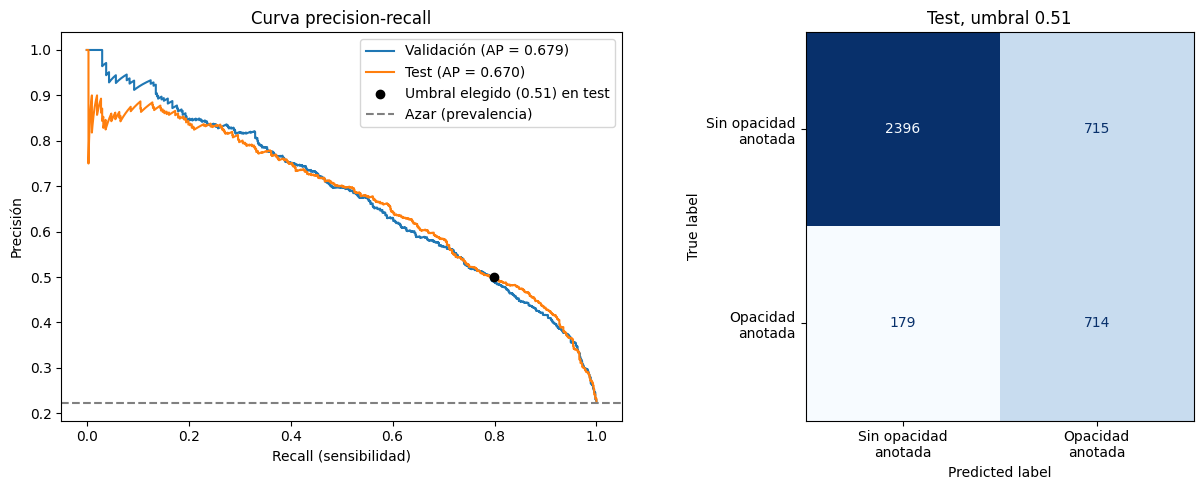

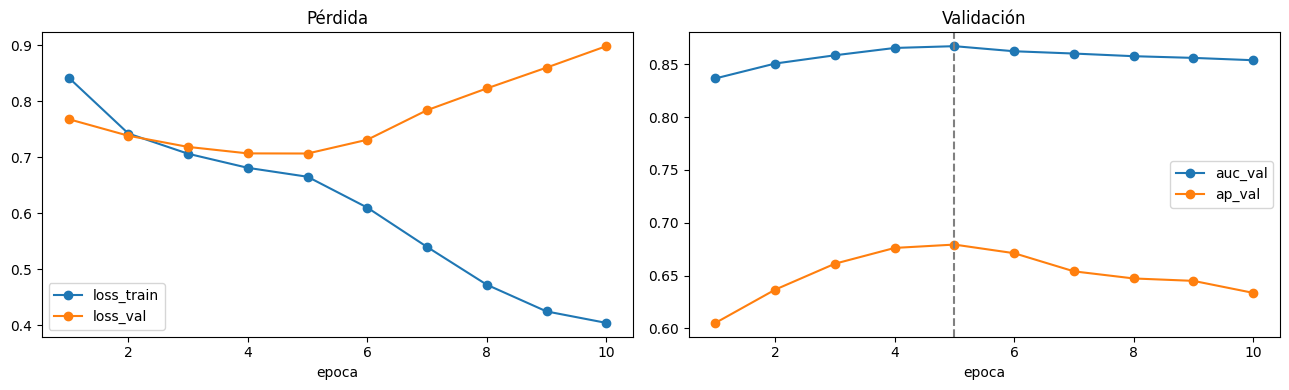

In [ ]:

pred_test = (p_test >= UMBRAL).astype(int)
por_clase = pd.DataFrame({"clase": CLASE[test_ids["patientId"]].values, "marcada_opacidad": pred_test})
por_clase = por_clase.groupby("clase")["marcada_opacidad"].agg(imágenes="size", marcadas="sum")
por_clase["% marcadas como opacidad"] = (100 * por_clase["marcadas"] / por_clase["imágenes"]).round(1)
display(por_clase)
metricas["clasificacion_por_clase"] = por_clase["% marcadas como opacidad"].to_dict()


POS = df.groupby("patientId")["position"].first()
posicion_test = POS[test_ids["patientId"]].values
por_pos = {p_: resumen(y_test[posicion_test == p_], p_test[posicion_test == p_], UMBRAL) for p_ in ["AP", "PA"]}
tabla_pos = pd.DataFrame(por_pos).T
tabla_pos.insert(0, "% con opacidad", [y_test[posicion_test == p_].mean() for p_ in ["AP", "PA"]])
display(tabla_pos[["% con opacidad", "auc", "ap", "recall", "especificidad", "precision", "tp", "fp", "fn", "tn"]].round(3))
metricas["clasificacion_por_posicion"] = {p_: {k: float(v) for k, v in r_.items()} for p_, r_ in por_pos.items()}

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nombre, yy, pp in [("Validación", y_val, p_val), ("Test", y_test, p_test)]:
    pr, rc, _ = precision_recall_curve(yy, pp)
    ax[0].plot(rc, pr, label=f"{nombre} (AP = {average_precision_score(yy, pp):.3f})")
r = metricas["clasificacion"]
ax[0].scatter([r["recall"]], [r["precision"]], color="black", zorder=3, label=f"Umbral elegido ({UMBRAL:.2f}) en test")
ax[0].axhline(y_test.mean(), color="gray", ls="--", label="Azar (prevalencia)")
ax[0].set_xlabel("Recall (sensibilidad)"); ax[0].set_ylabel("Precisión"); ax[0].set_title("Curva precision-recall"); ax[0].legend()
ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test),
                       display_labels=["Sin opacidad\nanotada", "Opacidad\nanotada"]).plot(ax=ax[1], cmap="Blues", colorbar=False)
ax[1].set_title(f"Test, umbral {UMBRAL:.2f}")
plt.tight_layout(); guardar_fig("04_clasificacion_pr_matriz"); plt.show()

h = pd.DataFrame(historial)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
h.plot(x="epoca", y=["loss_train", "loss_val"], ax=ax[0], marker="o", title="Pérdida")
h.plot(x="epoca", y=["auc_val", "ap_val"], ax=ax[1], marker="o", title="Validación")
ax[1].axvline(mejor_ep_cls, color="gray", ls="--")
plt.tight_layout(); guardar_fig("05_curvas_clasificacion"); plt.show()
h.to_csv(RES_DIR / "historial_clasificacion.csv", index=False)

- Casi todas las falsas alarmas son de la clase No Lung Opacity / Not Normal; las Normal casi no se marcan (1.8 %).
- Con el mismo umbral, en AP detecta más casos pero también da más falsas alarmas que en PA.
- En las curvas se ve que desde la época 6 la pérdida de validación sube: el modelo empieza a sobreajustar.

In [ ]:

del modelo, optim, scheduler, criterio, dl_train, dl_val, dl_test
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"Memoria GPU en uso: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

Memoria GPU en uso: 0.79 GB


- Liberamos la memoria de la GPU antes de pasar al detector.

## 5. Detección (cajas delimitadoras)



In [ ]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
import torchvision.transforms.functional as TF
from torchmetrics.detection import MeanAveragePrecision

EPOCHS_DET = 3
BATCH_DET = 8
DET_SIZE = min(IMG_W, 512)
SCORE_MIN = 0.5
IOU_MIN = 0.5
config.update({"epochs_det": EPOCHS_DET, "batch_det": BATCH_DET, "det_size": DET_SIZE,
               "score_min": SCORE_MIN, "iou_min": IOU_MIN})

class DetDataset(Dataset):
    def __init__(self, tabla, flip=False):
        self.ids, self.flip = tabla["patientId"].values, flip
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        pid = self.ids[i]
        with Image.open(img_paths[pid]) as im:
            img = TF.to_tensor(im.convert("RGB"))
        cajas = torch.tensor(CAJAS.get(pid, []), dtype=torch.float32).reshape(-1, 4)
        if self.flip and random.random() < 0.5:
            img = img.flip(-1)
            cajas[:, [0, 2]] = img.shape[-1] - cajas[:, [2, 0]]
        return img, {"boxes": cajas, "labels": torch.ones(len(cajas), dtype=torch.int64)}

pos_tr = train_ids[train_ids["Target"] == 1]
neg_tr = train_ids[train_ids["Target"] == 0].sample(len(pos_tr) // 2, random_state=SEED)
det_train_ids = pd.concat([pos_tr, neg_tr])
det_val_ids, _ = train_test_split(val_ids, train_size=1000, stratify=val_ids["Target"], random_state=SEED)

for nombre, s in [("train detección", det_train_ids), ("val detección", det_val_ids), ("test", test_ids)]:
    print(f"{nombre}: {len(s)} imágenes | con opacidad: {int(s['Target'].sum())} ({100 * s['Target'].mean():.1f} %)")
config["det_train"] = {"imagenes": len(det_train_ids), "positivas": int(det_train_ids["Target"].sum())}
config["det_val"] = {"imagenes": len(det_val_ids), "positivas": int(det_val_ids["Target"].sum())}
det_val_ids.to_csv(RES_DIR / "val_deteccion_ids.csv", index=False)

dl_det_train = make_loader(DetDataset(det_train_ids, flip=True), BATCH_DET, shuffle=True, detection=True)
dl_det_val = make_loader(DetDataset(det_val_ids), BATCH_DET, detection=True)
dl_det_test = make_loader(DetDataset(test_ids), BATCH_DET, detection=True)

det = fasterrcnn_resnet50_fpn_v2(weights="DEFAULT", min_size=DET_SIZE, max_size=DET_SIZE)
det.roi_heads.box_predictor = FastRCNNPredictor(det.roi_heads.box_predictor.cls_score.in_features, 2)
det = det.to(DEVICE)
optim_det = torch.optim.SGD(det.parameters(), lr=0.005, momentum=0.9, weight_decay=1e-4)

train detección: 6339 imágenes | con opacidad: 4226 (66.7 %)
val detección: 1000 imágenes | con opacidad: 223 (22.3 %)
test: 4004 imágenes | con opacidad: 893 (22.3 %)


- Faster R-CNN preentrenado en COCO; cambiamos la última capa a 2 clases (fondo y opacidad) y usamos imágenes de 512.
- Para entrenar tomamos todas las positivas de train y la mitad de esa cantidad de negativas, por tiempo en Colab.

Retomando desde Drive: 3 de 3 épocas ya entrenadas


,epoca,loss_classifier,loss_box_reg,loss_objectness,loss_rpn_box_reg,mAP@0.5,mAP
0,1,0.0888,0.1128,0.0167,0.0040,0.3764,0.1110
1,2,0.0765,0.1067,0.0104,0.0035,0.3994,0.1223
2,3,0.0713,0.1024,0.0087,0.0034,0.3880,0.1221


Mejor época (mAP@0.5 de validación): 2


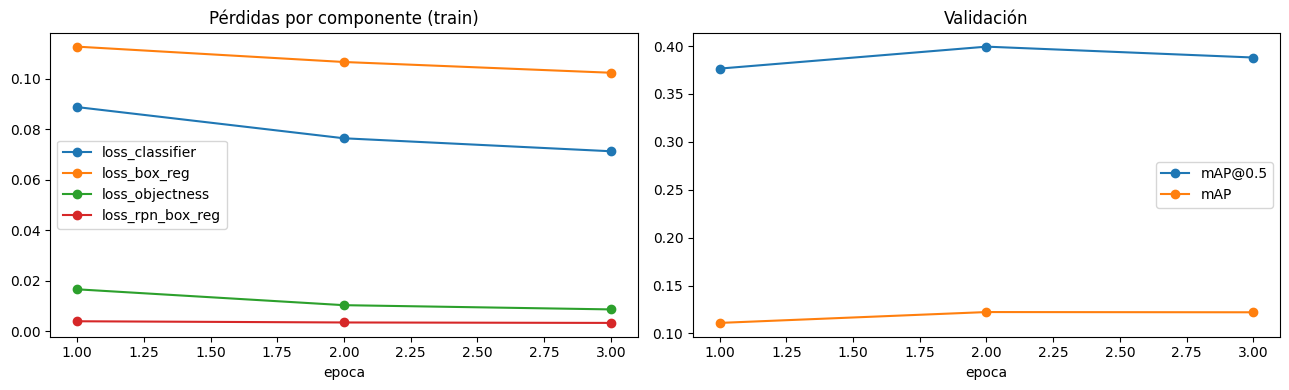

In [ ]:
@torch.no_grad()
def evaluar_det(m, dl):

    gc.collect(); m.eval(); metrica = MeanAveragePrecision(iou_type="bbox"); max_scores, preds = [], []
    for imgs, tgts in dl:
        salidas = [{k: v.cpu() for k, v in s.items()} for s in m([i.to(DEVICE) for i in imgs])]
        metrica.update(salidas, list(tgts))
        for s in salidas:
            max_scores.append(s["scores"].max().item() if len(s["scores"]) else 0.0)
            keep = s["scores"] >= SCORE_MIN
            preds.append((s["boxes"][keep], s["scores"][keep]))
    r = metrica.compute()
    return {"mAP@0.5": r["map_50"].item(), "mAP": r["map"].item()}, np.array(max_scores), preds

RUTA_DET = MODEL_DIR / "detector_fasterrcnn.pt"
RUTA_DET_ULT = MODEL_DIR / "detector_ultimo.pt"
mejor_map, mejor_ep_det, hist_det, inicio = -float("inf"), None, [], 0
if RUTA_DET_ULT.exists():
    ck = cargar(RUTA_DET_ULT)
    det.load_state_dict(ck["modelo"]); optim_det.load_state_dict(ck["optim"])
    mejor_map, mejor_ep_det, hist_det, inicio = ck["mejor_map"], ck["mejor_ep"], ck["historial"], ck["epoca"]
    del ck
    print(f"Retomando desde Drive: {inicio} de {EPOCHS_DET} épocas ya entrenadas")
for ep in range(inicio, EPOCHS_DET):
    gc.collect(); det.train(); suma = {}
    for imgs, tgts in tqdm(dl_det_train, desc=f"Época {ep + 1}/{EPOCHS_DET}"):
        imgs = [i.to(DEVICE) for i in imgs]
        tgts = [{k: v.to(DEVICE) for k, v in t.items()} for t in tgts]
        partes = det(imgs, tgts)
        loss = sum(partes.values())
        optim_det.zero_grad(); loss.backward(); optim_det.step()
        for k, v in partes.items():
            suma[k] = suma.get(k, 0) + v.item()
    r, _, _ = evaluar_det(det, dl_det_val)
    hist_det.append({"epoca": ep + 1, **{k: v / len(dl_det_train) for k, v in suma.items()}, **r})
    print({k: round(v, 4) for k, v in hist_det[-1].items()})
    if r["mAP@0.5"] > mejor_map:
        mejor_map, mejor_ep_det = r["mAP@0.5"], ep + 1
        guardar_ck({"modelo": det.state_dict(), "epoca": ep + 1}, RUTA_DET)
    guardar_ck({"modelo": det.state_dict(), "optim": optim_det.state_dict(), "epoca": ep + 1,
                "historial": hist_det, "mejor_map": mejor_map, "mejor_ep": mejor_ep_det,
                "config": config_simple()}, RUTA_DET_ULT)
display(pd.DataFrame(hist_det).round(4))
print("Mejor época (mAP@0.5 de validación):", mejor_ep_det)
config["mejor_epoca_det"] = mejor_ep_det

hd = pd.DataFrame(hist_det); hd.to_csv(RES_DIR / "historial_deteccion.csv", index=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
hd.plot(x="epoca", y=["loss_classifier", "loss_box_reg", "loss_objectness", "loss_rpn_box_reg"], ax=ax[0], marker="o", title="Pérdidas por componente (train)")
hd.plot(x="epoca", y=["mAP@0.5", "mAP"], ax=ax[1], marker="o", title="Validación")
plt.tight_layout(); guardar_fig("06_curvas_deteccion"); plt.show()

- Se entrenan 3 épocas y se guarda la de mejor mAP@0.5 en validación (la 2).

In [ ]:
from torchvision.ops import box_iou

def emparejar(boxes, scores, gt):

    boxes = boxes[scores.argsort(descending=True)]
    usada = torch.zeros(len(gt), dtype=torch.bool); ious = []
    if len(boxes) and len(gt):
        for fila in box_iou(boxes, gt):
            libre = fila.clone(); libre[usada] = -1
            v, j = libre.max(0)
            if v.item() >= IOU_MIN:
                usada[j] = True; ious.append(v.item())
    tp = len(ious)
    return tp, len(boxes) - tp, len(gt) - tp, ious

def metricas_cajas(filtro=None):

    TP = FP = FN = 0; ious = []
    tp_img, n_pred, iou_max = np.zeros(len(pids_test), int), np.zeros(len(pids_test), int), np.zeros(len(pids_test))
    for i, (pid, (b, s)) in enumerate(zip(pids_test, preds_test)):
        if filtro is not None and not filtro[i]:
            b, s = b[:0], s[:0]
        gt = torch.tensor(CAJAS.get(pid, []), dtype=torch.float32).reshape(-1, 4)
        tp, fp, fn, iu = emparejar(b, s, gt)
        TP += tp; FP += fp; FN += fn; ious += iu
        tp_img[i], n_pred[i] = tp, len(b)
        if len(b) and len(gt):
            iou_max[i] = box_iou(b, gt).max().item()
    res = {"recall_cajas": TP / (TP + FN), "precision_cajas": TP / max(TP + FP, 1),
           "imagenes_con_opacidad_localizadas": float((tp_img[pos] > 0).mean()),
           "imagenes_sin_opacidad_con_caja": float((n_pred[neg] > 0).mean()),
           "iou_medio_emparejadas": float(np.mean(ious)) if ious else float("nan"),
           "tp": TP, "fp": FP, "fn": FN}
    return res, tp_img, n_pred, iou_max

det.load_state_dict(cargar(RUTA_DET)["modelo"])
r_test, max_test, preds_test = evaluar_det(det, dl_det_test)
y_det = test_ids["Target"].values
pids_test = test_ids["patientId"].values
pos, neg = y_det == 1, y_det == 0
pasa = p_test >= UMBRAL

solo, tp_img, n_pred, iou_max = metricas_cajas()
casc, _, _, _ = metricas_cajas(pasa)
localizada, tiene_caja = tp_img > 0, n_pred > 0

metricas["deteccion"] = {**r_test, **solo,
    "imagenes_con_opacidad_con_alguna_caja_sin_exigir_ubicacion": float(tiene_caja[pos].mean())}
metricas["cascada"] = {"solo_detector": solo, "clasificador+detector": casc}

NOMBRES = {"recall_cajas": f"Recall por caja (IoU ≥ {IOU_MIN})", "precision_cajas": f"Precisión por caja (IoU ≥ {IOU_MIN})",
           "imagenes_con_opacidad_localizadas": "Imágenes con opacidad con ≥ 1 caja bien ubicada",
           "imagenes_sin_opacidad_con_caja": "Imágenes sin opacidad con alguna caja (falsa alarma)",
           "iou_medio_emparejadas": "IoU medio de las parejas aceptadas", "tp": "TP (cajas)", "fp": "FP (cajas)", "fn": "FN (cajas)"}
print(f"mAP@0.5 = {r_test['mAP@0.5']:.3f} | mAP@[0.5:0.95] = {r_test['mAP']:.3f}")
display(pd.DataFrame({"Solo detector": solo, "Clasificador + detector": casc}).rename(index=NOMBRES).round(3))
print(f"De {pos.sum()} imágenes con opacidad: {localizada[pos].sum()} con caja bien ubicada, "
      f"{(tiene_caja & ~localizada)[pos].sum()} solo con cajas mal ubicadas y {(~tiene_caja)[pos].sum()} sin caja. "
      f"Sin exigir ubicación, {100 * tiene_caja[pos].mean():.1f} % recibe alguna caja.")


posicion_det = POS[pids_test].values
display(pd.DataFrame({p_: {"Imágenes con opacidad localizadas": localizada[pos & (posicion_det == p_)].mean(),
                           "Imágenes sin opacidad con caja": tiene_caja[neg & (posicion_det == p_)].mean()}
                      for p_ in ["AP", "PA"]}).round(3))

mAP@0.5 = 0.369 | mAP@[0.5:0.95] = 0.126


,Solo detector,Clasificador + detector
Recall por caja (IoU ≥ 0.5),0.696,0.611
Precisión por caja (IoU ≥ 0.5),0.215,0.263
Imágenes con opacidad con ≥ 1 caja bien ubicada,0.761,0.641
Imágenes sin opacidad con alguna caja (falsa alarma),0.466,0.221
IoU medio de las parejas aceptadas,0.684,0.686
TP (cajas),988.000,868.000
FP (cajas),3603.000,2436.000
FN (cajas),432.000,552.000


De 893 imágenes con opacidad: 680 con caja bien ubicada, 184 solo con cajas mal ubicadas y 29 sin caja. Sin exigir ubicación, 96.8 % recibe alguna caja.


,AP,PA
Imágenes con opacidad localizadas,0.799,0.632
Imágenes sin opacidad con caja,0.742,0.316


- En test se mide el mAP y además se empareja cada caja predicha con una anotada (cuenta si el IoU es de al menos 0.5).
- El detector ubica bien la opacidad en el 76 % de las imágenes que la tienen, pero pone cajas en el 47 % de las que no.
- Si primero filtramos con el clasificador, esas falsas alarmas bajan al 22 %, pero las bien ubicadas bajan al 64 %.

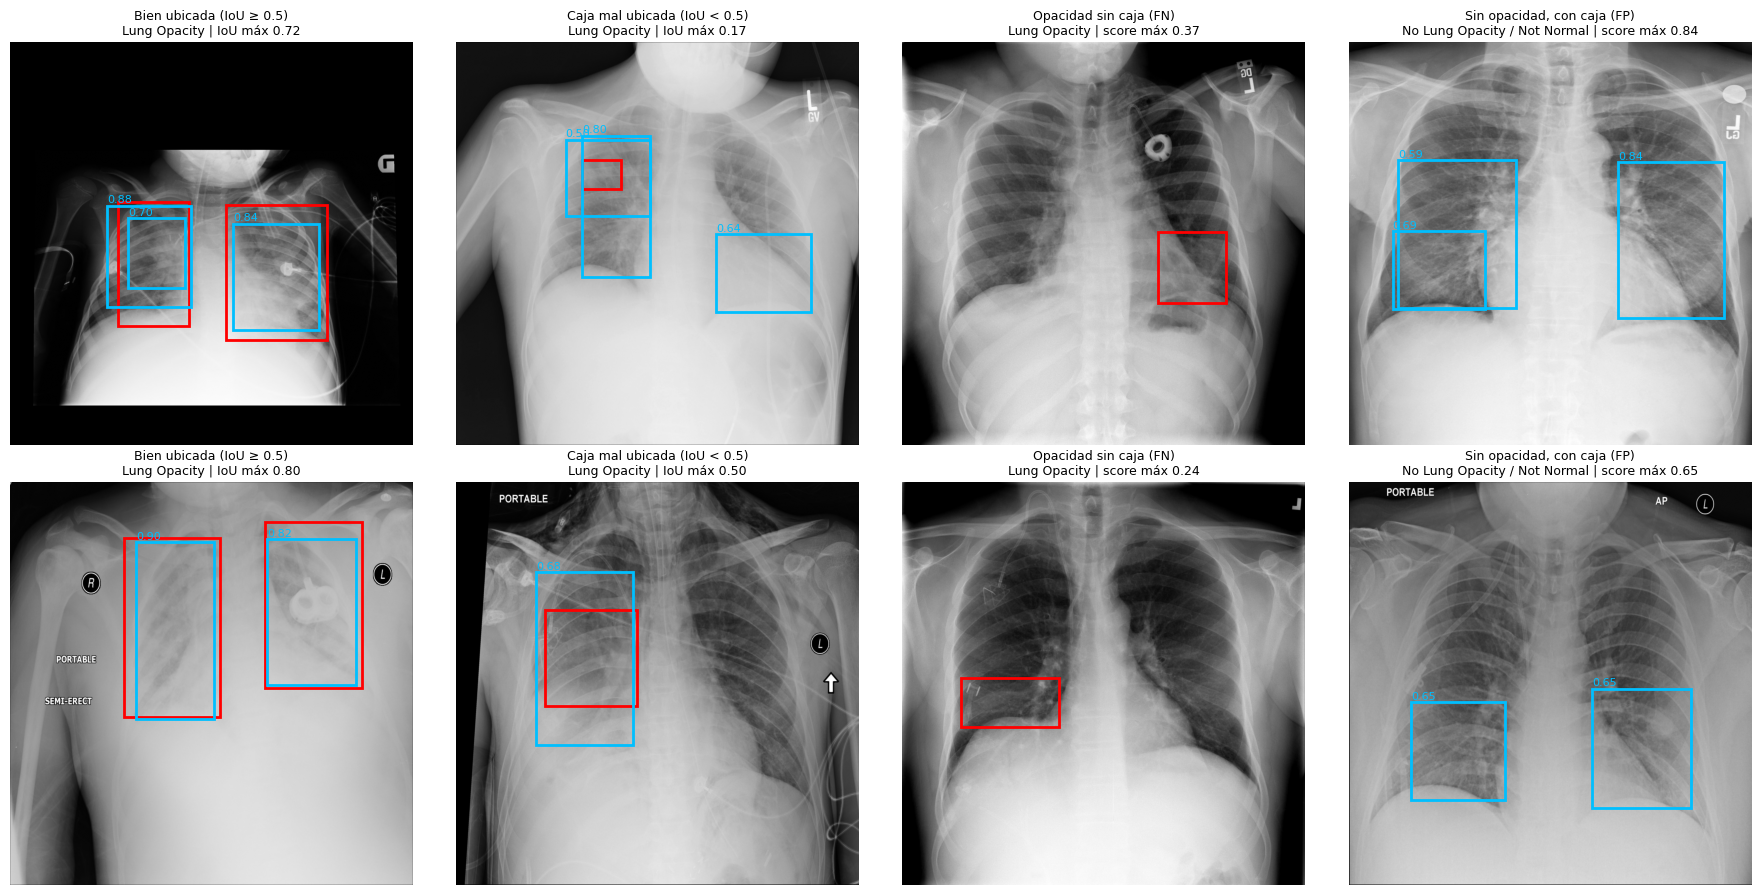

In [ ]:

def elegir(mascara, n=2):
    idx = np.flatnonzero(mascara)
    return list(np.random.default_rng(SEED).choice(idx, size=min(n, len(idx)), replace=False))

casos = [(f"Bien ubicada (IoU ≥ {IOU_MIN})", elegir(pos & localizada)),
         (f"Caja mal ubicada (IoU < {IOU_MIN})", elegir(pos & tiene_caja & ~localizada)),
         ("Opacidad sin caja (FN)", elegir(pos & ~tiene_caja)),
         ("Sin opacidad, con caja (FP)", elegir(neg & tiene_caja))]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for col, (nombre, idxs) in enumerate(casos):
    for fila in range(2):
        ax = axes[fila, col]
        if fila >= len(idxs):
            ax.axis("off"); continue
        i = idxs[fila]; pid = pids_test[i]
        dato = f"IoU máx {iou_max[i]:.2f}" if pos[i] else f"score máx {max_test[i]:.2f}"
        if pos[i] and not tiene_caja[i]:
            dato = f"score máx {max_test[i]:.2f}"
        mostrar(pid, ax, f"{nombre}\n{CLASE[pid]} | {dato}")
        for (x1, y1, x2, y2), sc in zip(*[t.tolist() for t in preds_test[i]]):
            ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="deepskyblue", linewidth=2))
            ax.text(x1, y1 - 8, f"{sc:.2f}", color="deepskyblue", fontsize=8)
plt.tight_layout(); guardar_fig("07_analisis_errores_deteccion"); plt.show()

- Ejemplos de aciertos y de cada tipo de error del detector (rojo: anotación, azul: predicción).

## 6. Resumen de resultados y conclusiones

In [ ]:
c, d, k = metricas["clasificacion"], metricas["deteccion"], metricas["cascada"]
display(Markdown(f'''
| Tarea | Modelo | Métrica (test) | Valor |
|---|---|---|---|
| Clasificación | ResNet-50 | AUC | {c["auc"]:.3f} |
| | | Average precision | {c["ap"]:.3f} |
| | | Recall (sensibilidad), umbral {c["umbral"]:.2f} | {c["recall"]:.3f} |
| | | Especificidad | {c["especificidad"]:.3f} |
| | | Precisión | {c["precision"]:.3f} |
| | | F1 | {c["f1"]:.3f} |
| Detección | Faster R-CNN ResNet-50 FPN v2 | mAP@0.5 | {d["mAP@0.5"]:.3f} |
| | | mAP@[0.5:0.95] | {d["mAP"]:.3f} |
| | | Recall por caja (IoU ≥ {IOU_MIN}, emparejamiento uno a uno) | {d["recall_cajas"]:.3f} |
| | | Precisión por caja (IoU ≥ {IOU_MIN}) | {d["precision_cajas"]:.3f} |
| | | Imágenes con opacidad con ≥ 1 caja bien ubicada | {d["imagenes_con_opacidad_localizadas"]:.3f} |
| | | Imágenes sin opacidad con ≥ 1 caja (falsa alarma) | {d["imagenes_sin_opacidad_con_caja"]:.3f} |
| | | IoU medio de las parejas aceptadas (n = {d["tp"]}) | {d["iou_medio_emparejadas"]:.3f} |
'''))

json.dump(metricas, open(RES_DIR / "metricas.json", "w"), indent=2, ensure_ascii=False)
json.dump(config, open(RES_DIR / "config.json", "w"), indent=2, ensure_ascii=False)
print(json.dumps(metricas, indent=2, ensure_ascii=False))
print("Resultados, figuras y modelos guardados en:", ROOT)


| Tarea | Modelo | Métrica (test) | Valor |
|---|---|---|---|
| Clasificación | ResNet-50 | AUC | 0.871 |
| | | Average precision | 0.670 |
| | | Recall (sensibilidad), umbral 0.51 | 0.800 |
| | | Especificidad | 0.770 |
| | | Precisión | 0.500 |
| | | F1 | 0.615 |
| Detección | Faster R-CNN ResNet-50 FPN v2 | mAP@0.5 | 0.369 |
| | | mAP@[0.5:0.95] | 0.126 |
| | | Recall por caja (IoU ≥ 0.5, emparejamiento uno a uno) | 0.696 |
| | | Precisión por caja (IoU ≥ 0.5) | 0.215 |
| | | Imágenes con opacidad con ≥ 1 caja bien ubicada | 0.761 |
| | | Imágenes sin opacidad con ≥ 1 caja (falsa alarma) | 0.466 |
| | | IoU medio de las parejas aceptadas (n = 988) | 0.684 |


{
  "clasificacion": {
    "umbral": 0.512,
    "auc": 0.8705323702370271,
    "ap": 0.670046549730211,
    "recall": 0.799552071668533,
    "especificidad": 0.7701703632272581,
    "precision": 0.4996501049685094,
    "f1": 0.6149870801033591,
    "tp": 714.0,
    "fp": 715.0,
    "fn": 179.0,
    "tn": 2396.0
  },
  "clasificacion_umbral_0.5": {
    "umbral": 0.5,
    "auc": 0.8705323702370271,
    "ap": 0.670046549730211,
    "recall": 0.8085106382978723,
    "especificidad": 0.7611700417872067,
    "precision": 0.4928327645051195,
    "f1": 0.6123833757421544,
    "tp": 722.0,
    "fp": 743.0,
    "fn": 171.0,
    "tn": 2368.0
  },
  "clasificacion_por_clase": {
    "Lung Opacity": 80.0,
    "No Lung Opacity / Not Normal": 39.4,
    "Normal": 1.8
  },
  "clasificacion_por_posicion": {
    "AP": {
      "umbral": 0.512,
      "auc": 0.8170040293658495,
      "ap": 0.7287335261332771,
      "recall": 0.8916184971098265,
      "especificidad": 0.5191605839416058,
      "precision": 0.

- Tabla final con las métricas de test; los resultados quedan guardados en Drive.